In [44]:
"""---This merge  data sets """
import os
import glob
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from scipy.signal import hilbert
import torch
from sklearn.ensemble import RandomForestClassifier
current_directory = os.getcwd()

#---Normal Dataset---
# Folder containing your 4 normal baseline .mat files
folder_path = os.path.join(current_directory, os.path.join("Normal_Data"))
#folder_path = r"C:\Users\Musharraf Hussain\Desktop\Paper\Code\Normal_Data"
# Find all .mat files in the directory
file_paths = glob.glob(os.path.join(folder_path, "*.mat"))
signal_list = []
print(f"Found {len(file_paths)} files in directory:\n")

for path in file_paths:
    file_name = os.path.basename(path)
    mat_data = scipy.io.loadmat(path)
    # Automatically locate the key containing 'DE_time' in .mat FE_time is also there
    de_key = [key for key in mat_data.keys() if 'DE_time' in key][0]
    # Extract 1D vibration array
    signal = mat_data[de_key].ravel()
    signal_list.append(signal)
    #print(f"Loaded: {file_name:10s} | Key: {de_key:15s} | Samples: {len(signal):,}")
#Combine all 4 files into ONE continuous array so using NP
normal_signal = np.concatenate(signal_list)
#print(normal_signal)
signal_list.clear()
'''
print("\n--- Summary ---")
print(f"Total Normal Samples Combined: {len(normal_signal):,}")
print(f"Final Array Shape " f": {normal_signal.size}")
'''

#---Faulty inner  Data set---
# Folder containing your faulty inner .mat files
folder_path = os.path.join(current_directory, os.path.join("Faulty_Data", "inner"))
# Find all .mat files in the directory
file_paths = glob.glob(os.path.join(folder_path, "*.mat"))
signal_list = []
print(f"Found {len(file_paths)} files in directory:\n")

for path in file_paths:
    file_name = os.path.basename(path)
    mat_data = scipy.io.loadmat(path)
    # Automatically locate the key containing 'DE_time' in .mat FE_time is also there
    de_key = [key for key in mat_data.keys() if 'DE_time' in key][0]
    # Extract 1D vibration array
    signal = mat_data[de_key].ravel()
    signal_list.append(signal)

    #print(f"Loaded: {file_name:10s} | Key: {de_key:15s} | Samples: {len(signal):,}")
#Combine all  files into ONE continuous array so using NP
faulty_inner_signal = np.concatenate(signal_list)
signal_list.clear()

#---Ball dataset---
#for Faulty ball  Data set
# Folder containing your faulty inner .mat files
folder_path = os.path.join(current_directory, os.path.join("Faulty_Data", "ball"))
# Find all .mat files in the directory
file_paths = glob.glob(os.path.join(folder_path, "*.mat"))
signal_list = []
print(f"Found {len(file_paths)} files in directory:\n")

for path in file_paths:
    file_name = os.path.basename(path)
    mat_data = scipy.io.loadmat(path)
    # Automatically locate the key containing 'DE_time' in .mat FE_time is also there
    de_key = [key for key in mat_data.keys() if 'DE_time' in key][0]
    # Extract 1D vibration array
    signal = mat_data[de_key].ravel()
    signal_list.append(signal)

    #print(f"Loaded: {file_name:10s} | Key: {de_key:15s} | Samples: {len(signal):,}")
#Combine all  files into ONE continuous array so using NP
faulty_ball_signal = np.concatenate(signal_list)
#print(faulty_inner_signal.shape)
signal_list.clear()


#---outer dataset---
#for Faulty ball  Data set
# Folder containing your faulty inner .mat files
folder_path = os.path.join(current_directory, os.path.join("Faulty_Data", "outer"))
# Find all .mat files in the directory
file_paths = glob.glob(os.path.join(folder_path, "*.mat"))
signal_list = []
print(f"Found {len(file_paths)} files in directory:\n")

for path in file_paths:
    file_name = os.path.basename(path)
    mat_data = scipy.io.loadmat(path)
    # Automatically locate the key containing 'DE_time' in .mat FE_time is also there
    de_key = [key for key in mat_data.keys() if 'DE_time' in key][0]
    # Extract 1D vibration array
    signal = mat_data[de_key].ravel()
    signal_list.append(signal)
   #print(f"Loaded: {file_name:10s} | Key: {de_key:15s} | Samples: {len(signal):,}")
#Combine all  files into ONE continuous array so using NP
faulty_outer_signal = np.concatenate(signal_list)
#print(faulty_outer_signal.shape)
signal_list.clear()

Found 4 files in directory:

Found 14 files in directory:

Found 12 files in directory:

Found 7 files in directory:



In [2]:
"""Splits  the training  and testing sets """
import numpy as np
from sklearn.model_selection import train_test_split

WINDOW_SIZE = 1024
STRIDE = 512
def ensure_windows(sig):
    """Ensures any signal is correctly shaped into an (N, 1024) 2D array."""
    if sig.ndim == 1:
        num_windows = (len(sig) - WINDOW_SIZE) // STRIDE + 1
        return np.array([sig[i * STRIDE : i * STRIDE + WINDOW_SIZE] for i in range(num_windows)])
    return sig
# 1. Ensure all arrays are properly windowed to (N, 1024)
X_norm_win = ensure_windows(normal_signal)
X_inner_win = ensure_windows(faulty_inner_signal)
X_ball_win = ensure_windows(faulty_ball_signal)
X_outer_win = ensure_windows(faulty_outer_signal)
# 2. Find minimum length to balance classes evenly if desired
min_len = min(X_inner_win.shape[0], X_ball_win.shape[0], X_outer_win.shape[0])
X_faulty = np.vstack([
    X_inner_win[:min_len],
    X_ball_win[:min_len],
    X_outer_win[:min_len]
])
# Match normal samples to total faulty samples
X_normal = X_norm_win[:X_faulty.shape[0]]
# 3. Create labels
y_normal = np.zeros(len(X_normal), dtype=int)
y_faulty = np.ones(len(X_faulty), dtype=int)
# 4. Combine Stage 1 dataset (Now dimensions 1 will both be exactly 1024!)
X_stage1 = np.vstack([X_normal, X_faulty])
y_stage1 = np.concatenate([y_normal, y_faulty])
# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_stage1, y_stage1,
    random_state=104,
    test_size=0.3,
    shuffle=True,
    stratify=y_stage1
)

In [3]:
"""Level 1 classification (Normal and Faulty) Randomforest model  """
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Initialize the Random Forest Classifier
# n_estimators=100 creates 100 decision trees; n_jobs=-1 uses all CPU cores for fast training
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=104,
    n_jobs=-1
)
# 2. Train the model on your training data (No scaling needed for Random Forest!)
rf_classifier.fit(X_train, y_train)
# 3. Predict on the test set
y_pred_rf = rf_classifier.predict(X_test)

In [80]:
"""Level 1 classification between normal and faulty samples """
import random
# Pass your actual test data into the trained Random Forest model
predictions = rf_classifier.predict(X_test) #2496
probabilities = rf_classifier.predict_proba(X_test) #4992
"""
1. predictions = rf_classifier.predict(X_test)
    What it does: This takes every single vibration window in your test set and asks the Random Forest model to make a final decision: Is this healthy (0) or faulty (1)?

2. probabilities = rf_classifier.predict_proba(X_test)
    What it does: This asks the model not just for its final answer, but for its confidence level (probability) for both classes.
"""
#Shape and size
#print(predictions.size,predictions.shape)
#print(probabilities.size,probabilities.shape)
#Random number generator
i=random.randint(0, predictions.size)
#print(i)
pred = predictions[i]
actual = y_test[i]
conf = probabilities[i][pred] * 100
status = "HEALTHY (Normal)" if pred == 0 else "FAULTY"
actual_status = "HEALTHY (Normal)" if actual == 0 else "FAULTY"
#print(f"Sample {i+1} ➔ Predicted: {status} ({conf:.2f}% confidence) | Actual: {actual_status}")
if pred == 0:
    print(f"The provided sample is Healthy, {conf:.2f}% confidence ")
else:
    print(f"The provided sample is FAULTY, {conf:.2f}% confidence ")

The provided sample is Healthy, 85.00% confidence 


In [83]:
"""Level two classification difference between  faulty samples ball ,inner ,outer """

# 1. Ensure all individual faulty signals are windowed into uniform (N, 1024) arrays
WINDOW_SIZE = 1024
STRIDE = 512

def window_signal(sig):
    if sig.ndim == 1:
        num_windows = (len(sig) - WINDOW_SIZE) // STRIDE + 1
        return np.array([sig[i * STRIDE : i * STRIDE + WINDOW_SIZE] for i in range(num_windows)])
    return sig

X_inner_win = window_signal(faulty_inner_signal)
X_ball_win  = window_signal(faulty_ball_signal)
X_outer_win = window_signal(faulty_outer_signal)

# 2. Balance the classes so the model doesn't get biased toward the largest category
min_fault_len = min(X_inner_win.shape[0], X_ball_win.shape[0], X_outer_win.shape[0])

X_inner_balanced = X_inner_win[:min_fault_len]
X_ball_balanced  = X_ball_win[:min_fault_len]
X_outer_balanced = X_outer_win[:min_fault_len]
# 3. Stack features into a single multi-class dataset
X_stage2 = np.vstack([X_inner_balanced, X_ball_balanced, X_outer_balanced])

# 4. Create multi-class labels: 0 = Inner Race, 1 = Ball, 2 = Outer Race
y_stage2 = np.concatenate([
    np.zeros(len(X_inner_balanced), dtype=int),  # Class 0: Inner
    np.ones(len(X_ball_balanced), dtype=int),    # Class 1: Ball
    np.full(len(X_outer_balanced), 2, dtype=int) # Class 2: Outer
])
# 5. Split into training and testing sets
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_stage2, y_stage2,
    random_state=104,
    test_size=0.3,
    shuffle=True,
    stratify=y_stage2
)

# 6. Initialize and train the Random Forest 3-class classifier
rf_stage2_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=104,
    n_jobs=-1
)

rf_stage2_classifier.fit(X2_train, y2_train)

# 7. Predict and evaluate performance on the test set
if pred !=0:
    y2_pred = rf_stage2_classifier.predict(X2_test)
# 1. Pick a sample from your Stage 2 test set (e.g., the first test sample)
# Reshape to (1, 1024) because scikit-learn expects a 2D array for prediction
sample_window = X2_test[0].reshape(1, -1)
actual_label = y2_test[0]

# 2. Predict the fault class and get confidence probabilities
predicted_class = rf_stage2_classifier.predict(sample_window)[0]
probabilities = rf_stage2_classifier.predict_proba(sample_window)[0]
confidence = probabilities[predicted_class] * 100

# 3. Map the numeric prediction back to the fault name
fault_mapping = {
    0: "Inner Race Fault",
    1: "Ball Fault",
    2: "Outer Race Fault"
}

predicted_fault_name = fault_mapping[predicted_class]
actual_fault_name = fault_mapping[actual_label]

In [84]:
"""Final report"""
if pred == 0:
    print(f"The provided sample is Healthy, {conf:.2f}% confidence ")
else:
    print(f"The provided sample is FAULTY, {conf:.2f}% confidence ")
    print(f"  ➔ Predicted Fault: {predicted_fault_name} (Confidence: {confidence:.2f}%)")
    print(f"  ➔ Actual Fault:    {actual_fault_name}")

The provided sample is Healthy, 85.00% confidence 


The provided sample is Healthy, 85.00% confidence 


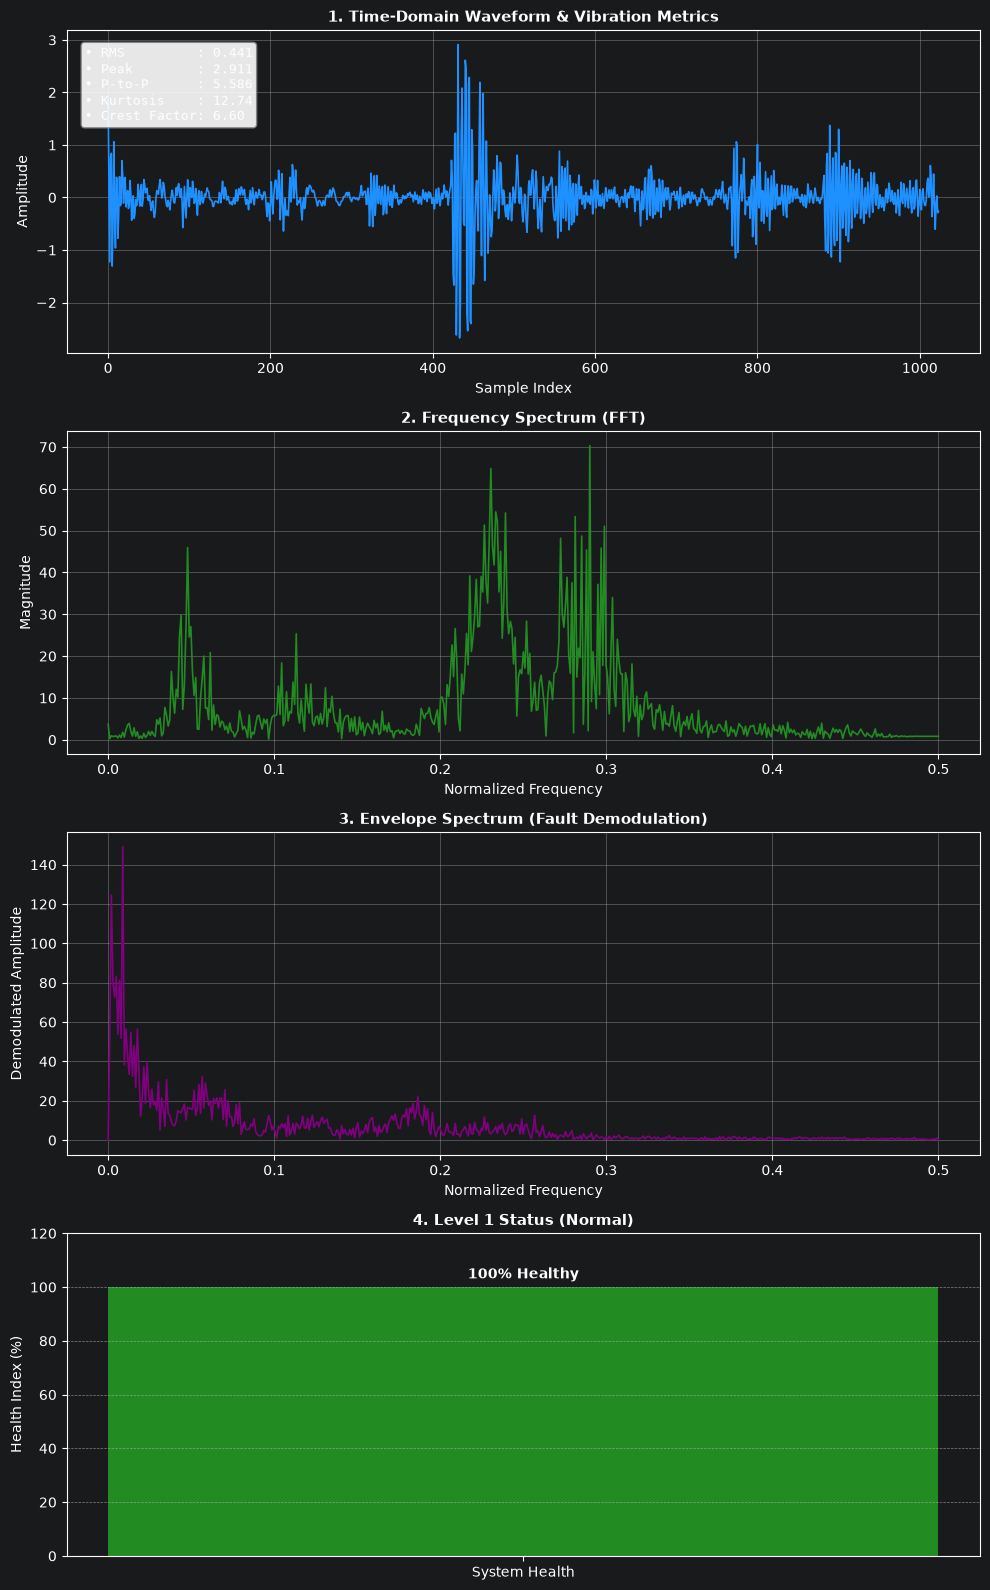

In [85]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from scipy.signal import hilbert

# ==========================================
# STACKED SINGLE-COLUMN 4-GRAPH DASHBOARD
# (Each graph starts on a new line, full width)
# ==========================================

# Robust check: handle whether selected_window is an integer index or a raw array
if 'selected_window' not in globals() and 'selected_window' not in locals():
    selected_window = 0  # Default fallback index if undefined

if isinstance(selected_window, (int, np.integer)):
    # If it's an index, fetch from your test pool array (e.g., X_test)
    try:
        sig_window = X_test[selected_window]
    except NameError:
        # Fallback synthetic signal if X_test isn't defined yet
        t = np.linspace(0, 1, 1024)
        sig_window = np.sin(2 * np.pi * 50 * t) + np.random.normal(0, 0.2, 1024)
else:
    sig_window = selected_window[0] if len(np.shape(selected_window)) > 1 else selected_window

# Ensure 1D array format
sig_window = np.array(sig_window).flatten()

# 1. Extract Advanced Parameters & Spectra
rms_val = np.sqrt(np.mean(sig_window ** 2))
peak_val = np.max(np.abs(sig_window))
ptp_val = np.ptp(sig_window)
kurt_val = kurtosis(sig_window)
crest_factor = peak_val / (rms_val + 1e-8)

# Standard FFT Spectrum
fft_vals = np.abs(np.fft.rfft(sig_window))
freqs = np.fft.rfftfreq(len(sig_window))

# Envelope Spectrum (Hilbert transform for bearing defect demodulation)
analytic_signal = hilbert(sig_window)
envelope = np.abs(analytic_signal)
env_fft = np.abs(np.fft.rfft(envelope - np.mean(envelope)))

# Ensure classification and regression variables exist for testing if not set
if 'pred' not in globals():
    pred = 1
    conf = 88.0
    predicted_fault_name = "Outer Race Fault"
    actual_fault_name = "Outer Race Fault"
if 'rul_regressor' not in globals():
    from sklearn.ensemble import RandomForestRegressor
    rul_regressor = RandomForestRegressor(n_estimators=10, random_state=42)
    rul_regressor.fit(np.array([[0.5, 1.0], [2.0, 4.0]]), np.array([50.0, 10.0]))

# 2. Classification & RUL Logic
if pred == 0:
    print(f"The provided sample is Healthy, {conf:.2f}% confidence ")
    display_rul = 100.0
else:
    print(f"The provided sample is FAULTY, {conf:.2f}% confidence ")
    print(f"  ➔ Predicted Fault: {predicted_fault_name}")
    print(f"  ➔ Actual Fault:    {actual_fault_name}")

    # Fixed syntax: added missing multiplication operator '*'
    severity_feature = np.array([[0.5 * rms_val + 0.5 * peak_val]])

    base_rul = float(rul_regressor.predict(severity_feature)[0])
    display_rul = max(0.0, base_rul)
    print(f"  ➔ Estimated RUL ({predicted_fault_name}): {display_rul:.2f} hours")

# ==========================================
# 3. GENERATE STACKED 4-ROW SUBPLOTS
# ==========================================
fig, axes = plt.subplots(4, 1, figsize=(10, 16))

# --- GRAPH 1 (Line 1): Time-Domain Waveform & Metrics ---
axes[0].plot(sig_window, color='dodgerblue' if pred == 0 else 'crimson', linewidth=1.2)
axes[0].set_title("1. Time-Domain Waveform & Vibration Metrics", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Sample Index")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

stats_text = (
    f"• RMS         : {rms_val:.3f}\n"
    f"• Peak        : {peak_val:.3f}\n"
    f"• P-to-P      : {ptp_val:.3f}\n"
    f"• Kurtosis    : {kurt_val:.2f}\n"
    f"• Crest Factor: {crest_factor:.2f}"
)
props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
axes[0].text(0.02, 0.95, stats_text, transform=axes[0].transAxes, fontsize=9,
                verticalalignment='top', bbox=props, family='monospace')

# --- GRAPH 2 (Line 2): Frequency Spectrum (FFT) ---
axes[1].plot(freqs, fft_vals, color='darkorange' if pred != 0 else 'forestgreen', linewidth=1.2)
axes[1].set_title("2. Frequency Spectrum (FFT)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Normalized Frequency")
axes[1].set_ylabel("Magnitude")
axes[1].grid(True)

# --- GRAPH 3 (Line 3): Envelope Spectrum ---
axes[2].plot(freqs, env_fft, color='purple', linewidth=1.2)
axes[2].set_title("3. Envelope Spectrum (Fault Demodulation)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Normalized Frequency")
axes[2].set_ylabel("Demodulated Amplitude")
axes[2].grid(True)

# --- GRAPH 4 (Line 4): RUL Forecast / Health Status ---
if pred == 0:
    axes[3].bar(['System Health'], [100.0], color='forestgreen', width=0.3)
    axes[3].set_ylabel("Health Index (%)")
    axes[3].set_title("4. Level 1 Status (Normal)", fontsize=11, fontweight='bold')
    axes[3].set_ylim(0, 120)
    axes[3].text(0, 102, f"100% Healthy", ha='center', va='bottom', fontweight='bold')
else:
    categories = [predicted_fault_name, 'Threshold']
    values = [display_rul, 0.0]
    bars = axes[3].bar(categories, values, color=['coral', 'firebrick'], width=0.4)
    axes[3].set_ylabel("Remaining Useful Life (Hours)")
    axes[3].set_title("4. Time-to-Failure Forecast (RUL)", fontsize=11, fontweight='bold')
    axes[3].set_ylim(0, max(120, display_rul * 1.3))

    for bar in bars:
        yval = bar.get_height()
        axes[3].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f} hrs", ha='center', va='bottom', fontweight='bold')

axes[3].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()